# Practical assignment: Hard Negative Mining with Fashion-MNIST

**Human-Centred AI — Computer Vision**

In this notebook you will train a small image classifier and improve it using **hard negative mining**. The goal is to understand the idea by running a working experiment, inspecting selected images, and comparing two models.

**Estimated time:** 45–60 minutes, depending on hardware and dataset download.

**You do not need advanced Python.** Run the cells from top to bottom and answer the questions near the end. The training code is provided.

## The idea

We will teach a model to answer one question: **Is this image a sneaker?**

- A sneaker is a **positive** example.
- Any other Fashion-MNIST item is a **negative** example.
- A **hard negative** is a non-sneaker that the model mistakenly considers sneaker-like.

The workflow:

1. Train a model with a small set of randomly chosen negatives.
2. Ask the model to score a separate pool of negative images.
3. Select the negatives with the highest sneaker scores.
4. Add those images to training and train again.
5. Compare the baseline and hard-negative model on a test set neither model has trained on.

## 0. Setup

Run this cell first. The notebook uses PyTorch and torchvision. These are preinstalled in many teaching environments (including common GPU notebook environments).

If an import fails, ask your instructor before installing packages. The Fashion-MNIST data will download automatically.

In [1]:
# Imports and reproducibility
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Using: cuda
GPU: NVIDIA RTX A3000 Laptop GPU


## 1. Load Fashion-MNIST

Fashion-MNIST contains 28×28 grayscale images from 10 clothing categories. We turn it into a **binary classification** problem:

- **Positive (label 1):** Sneaker (original Fashion-MNIST class 7)
- **Negative (label 0):** Any other clothing item

This makes hard negative mining easy to see: a hard negative is a non-sneaker image that the model gives a high sneaker score.

In [2]:
# Download happens only the first time. The dataset is small.
train_raw = datasets.FashionMNIST(root="data", train=True, download=True)
test_raw  = datasets.FashionMNIST(root="data", train=False, download=True)

# Convert images to float tensors in the range [0, 1].
X_train = train_raw.data.unsqueeze(1).float() / 255.0
y_train = (train_raw.targets == 7).long()   # 1 = sneaker, 0 = not sneaker
X_test = test_raw.data.unsqueeze(1).float() / 255.0
y_test = (test_raw.targets == 7).long()

print("Training images:", len(X_train))
print("Test images:", len(X_test))
print("Positive training examples (sneakers):", int(y_train.sum()))
print("Negative training examples (not sneakers):", int((y_train == 0).sum()))

Training images: 60000
Test images: 10000
Positive training examples (sneakers): 6000
Negative training examples (not sneakers): 54000


### Look at a few examples

The title above each image tells you its binary label. Notice that the negative class contains many visually different types of clothing.

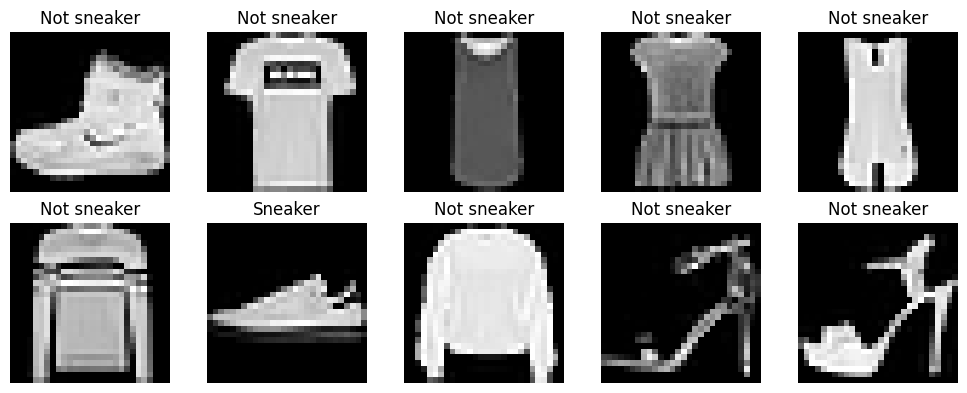

In [3]:
class_names = ["Not sneaker", "Sneaker"]
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, range(10)):
    ax.imshow(X_train[idx, 0], cmap="gray")
    ax.set_title(class_names[int(y_train[idx])])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Create a small training set and a separate mining pool

To demonstrate mining, we deliberately do **not** start with every negative example.

- We use 2,500 sneaker images as positives.
- We start with 1,500 randomly selected negatives.
- We keep 5,000 additional negatives in a separate **candidate pool**.

The model will inspect the candidate pool and select the negatives it currently finds most confusing. The test set stays untouched until evaluation.

In [4]:
g = torch.Generator().manual_seed(SEED)
positive_ids = torch.where(y_train == 1)[0]
negative_ids = torch.where(y_train == 0)[0]
positive_ids = positive_ids[torch.randperm(len(positive_ids), generator=g)]
negative_ids = negative_ids[torch.randperm(len(negative_ids), generator=g)]

N_POSITIVE = 2500
N_INITIAL_NEGATIVE = 1500
N_CANDIDATE = 5000

pos_ids = positive_ids[:N_POSITIVE]
initial_neg_ids = negative_ids[:N_INITIAL_NEGATIVE]
candidate_ids = negative_ids[N_INITIAL_NEGATIVE:N_INITIAL_NEGATIVE + N_CANDIDATE]

X_pos, y_pos = X_train[pos_ids], y_train[pos_ids]
X_initial_neg = X_train[initial_neg_ids]
X_pool = X_train[candidate_ids]

print("Initial positives:", len(X_pos))
print("Initial negatives:", len(X_initial_neg))
print("Unseen negative candidates:", len(X_pool))

Initial positives: 2500
Initial negatives: 1500
Unseen negative candidates: 5000


## 3. Build a small convolutional neural network

A compact CNN is enough for this classroom experiment. The final layer returns **one logit**. Applying `sigmoid` converts it into a score between 0 and 1: higher means "more likely to be a sneaker".

In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten()
        )
        self.classifier = nn.Linear(32 * 7 * 7, 1)

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

def make_model():
    return SmallCNN().to(device)

def make_loader(X_pos, X_neg, batch_size=128):
    X = torch.cat([X_pos, X_neg])
    y = torch.cat([
        torch.ones(len(X_pos)),
        torch.zeros(len(X_neg))
    ])
    dataset = TensorDataset(X, y)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)

def train_model(model, loader, epochs=2):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.BCEWithLogitsLoss()

    for epoch in range(epochs):
        total_loss = 0.0
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = loss_fn(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(images)

        print(f"Epoch {epoch+1}/{epochs} - loss: {total_loss / len(loader.dataset):.4f}")
    return model

## 4. Train a baseline model (random negatives)

First train on the initial random negatives only. We call this the **baseline**. We will compare it with a model trained using hard negative mining.

In [6]:
baseline = make_model()
baseline_loader = make_loader(X_pos, X_initial_neg)
start = time.time()
baseline = train_model(baseline, baseline_loader, epochs=6)
print(f"Baseline training time: {time.time() - start:.1f} seconds")

Epoch 1/6 - loss: 0.4148
Epoch 2/6 - loss: 0.1457
Epoch 3/6 - loss: 0.1347
Epoch 4/6 - loss: 0.1271
Epoch 5/6 - loss: 0.1213
Epoch 6/6 - loss: 0.1128
Baseline training time: 1.3 seconds


## 5. Hard negative mining

For every candidate negative image, the model predicts a sneaker score. A negative image with a **high sneaker score** is a hard negative: it is not a sneaker, but the model is tempted to call it one.

We select the highest-scoring candidates, add them to the training negatives, and train for another short round. We repeat this twice.

**Important:** The candidate pool contains only negative examples. We know their true labels because we constructed the pool from Fashion-MNIST labels; in a real application, labels must be available or checked.

In [7]:
def mine_hard_negatives(model, X_candidates, number_to_mine=750):
    model.eval()
    scores = []
    with torch.no_grad():
        for start_idx in range(0, len(X_candidates), 256):
            batch = X_candidates[start_idx:start_idx + 256].to(device)
            probabilities = torch.sigmoid(model(batch))
            scores.append(probabilities.cpu())

    scores = torch.cat(scores)
    k = min(number_to_mine, len(X_candidates))
    hard_ids = torch.topk(scores, k=k).indices
    return hard_ids, scores

# Start again from a fresh model, using the same initial examples.
hnm_model = make_model()
X_mined_neg = X_initial_neg.clone()
remaining_pool = X_pool.clone()

# First short training round
hnm_loader = make_loader(X_pos, X_mined_neg)
hnm_model = train_model(hnm_model, hnm_loader, epochs=2)

# Mine and train for two rounds
mined_counts = []
for round_number in range(2):
    hard_ids, candidate_scores = mine_hard_negatives(hnm_model, remaining_pool)
    hard_images = remaining_pool[hard_ids]
    mined_counts.append(len(hard_images))

    # Add selected hard negatives to the training set.
    X_mined_neg = torch.cat([X_mined_neg, hard_images])

    # Remove selected examples so they are not mined again.
    keep = torch.ones(len(remaining_pool), dtype=torch.bool)
    keep[hard_ids] = False
    remaining_pool = remaining_pool[keep]

    print(f"Round {round_number + 1}: added {len(hard_images)} hard negatives")
    hnm_loader = make_loader(X_pos, X_mined_neg)
    hnm_model = train_model(hnm_model, hnm_loader, epochs=2)

print("Total negative training examples after mining:", len(X_mined_neg))

Epoch 1/2 - loss: 0.3874
Epoch 2/2 - loss: 0.1404
Round 1: added 750 hard negatives
Epoch 1/2 - loss: 0.2755
Epoch 2/2 - loss: 0.2394
Round 2: added 750 hard negatives
Epoch 1/2 - loss: 0.1860
Epoch 2/2 - loss: 0.1626
Total negative training examples after mining: 3000


### Inspect the mined examples

These are examples selected because the current model gave them the highest sneaker scores, even though they are all non-sneakers. The score shown is the model's predicted sneaker probability.

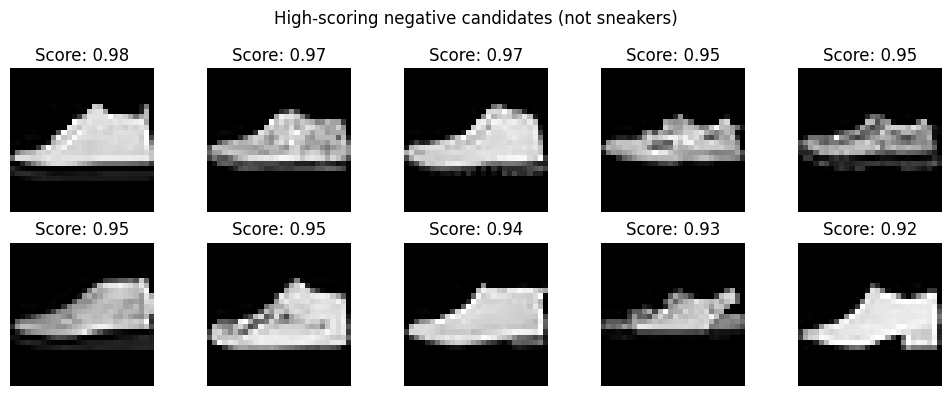

In [8]:
# Show the top-scoring examples from the original candidate pool.
hard_ids, scores = mine_hard_negatives(hnm_model, X_pool, number_to_mine=10)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, hard_ids):
    ax.imshow(X_pool[idx, 0], cmap="gray")
    ax.set_title(f"Score: {scores[idx]:.2f}")
    ax.axis("off")
plt.suptitle("High-scoring negative candidates (not sneakers)")
plt.tight_layout()
plt.show()

## 6. Evaluate on the same untouched test set

We use the same test set for both models. The threshold is 0.5:

- score ≥ 0.5 → predict sneaker
- score < 0.5 → predict not sneaker

We report **recall** (how many real sneakers are found) and **false positive rate** (how many non-sneakers are incorrectly called sneakers). Hard negative mining is particularly intended to reduce false positives.

In [9]:
def evaluate(model, X, y, threshold=0.5):
    model.eval()
    all_scores = []
    with torch.no_grad():
        for start_idx in range(0, len(X), 256):
            batch = X[start_idx:start_idx + 256].to(device)
            all_scores.append(torch.sigmoid(model(batch)).cpu())
    scores = torch.cat(all_scores)
    predictions = (scores >= threshold).long()

    positive = (y == 1)
    negative = (y == 0)
    recall = (predictions[positive] == 1).float().mean().item()
    false_positive_rate = (predictions[negative] == 1).float().mean().item()
    accuracy = (predictions == y).float().mean().item()
    return accuracy, recall, false_positive_rate

baseline_metrics = evaluate(baseline, X_test, y_test)
hnm_metrics = evaluate(hnm_model, X_test, y_test)

print("                 Accuracy   Recall   False positive rate")
print(f"Baseline         {baseline_metrics[0]:.3f}      {baseline_metrics[1]:.3f}       {baseline_metrics[2]:.3f}")
print(f"Hard negative    {hnm_metrics[0]:.3f}      {hnm_metrics[1]:.3f}       {hnm_metrics[2]:.3f}")

                 Accuracy   Recall   False positive rate
Baseline         0.897      0.996       0.114
Hard negative    0.973      0.956       0.025


## 7. Student assignment

Answer these questions in your own words. You do **not** need to write additional Python.

1. In this notebook, what makes an image a *negative* example?
2. Why do we select negative images with the highest predicted sneaker scores?
3. What is the difference between the initial random negatives and the mined hard negatives?
4. Compare the baseline and hard-negative model's **false positive rates**. Did hard negative mining reduce false positives in your run?
5. What happened to recall? Is there a trade-off between reducing false positives and finding all sneakers?
6. Why must we keep the test set separate from the mining pool?
7. Give one reason why mining only the hardest examples could be a bad idea.

**Optional experiment (change one number only):** Change `number_to_mine=750` in the mining function call to `number_to_mine=150`. Run the mining and evaluation cells again. How does selecting fewer hard negatives affect the result?

### What to submit

Submit this notebook with:
- the two evaluation results,
- your answers to questions 1–7,
- one sentence describing whether hard negative mining helped in your run.

### Key idea

Hard negative mining does not create new labels. It changes **which known negative examples the model sees during training**, prioritising examples that currently look most like positives to the model.